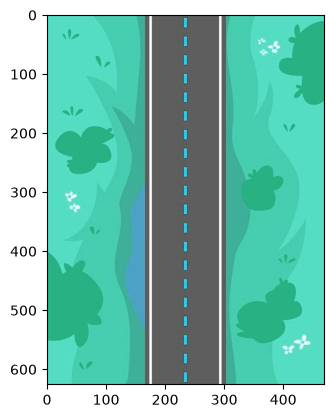

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
img = cv.imread('road2.jpg')

plt.imshow(img, cmap='gray')
plt.show()

In [2]:
AMBULADE_CONSTANT = np.array([0.299, 0.587, 0.114])
def convert2grey(img):
    return np.round(img[...,:3] @ AMBULADE_CONSTANT).astype(np.uint8)

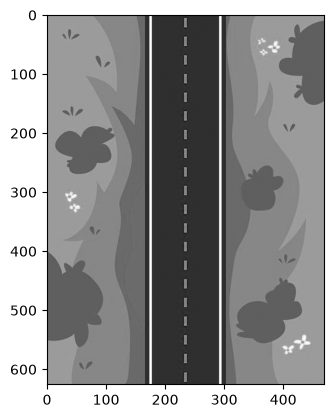

In [3]:
grey = convert2grey(img)
plt.imshow(grey, cmap='grey')
plt.show()

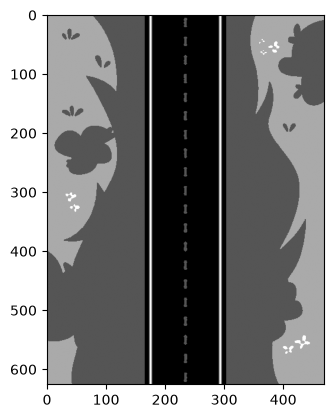

In [4]:
horizontal_direction = np.array([
    [0, 0, 0],
    [-1, 0, 1],
    [0, 0, 0]
])

vertical_direction = np.array([
    [0, -1, 0],
    [0, 0, 0],
    [0, 1, 0]
])

def gaussian_kernel(k, sigma=1):
    """Generate (2*k + 1) x (2*k + 1) Gaussian kernel"""
    size = 2 * k + 1
    kernel = np.zeros((size, size))
    for i in range(size):
        for j in range(size):
            x = i - k
            y = j - k
            kernel[i, j] = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    kernel *= 1 / (2 * np.pi * sigma**2)
    return kernel / size**2


filtered = cv.filter2D(grey, -1, gaussian_kernel(3, 1))
plt.imshow(filtered, cmap='gray')
plt.show()

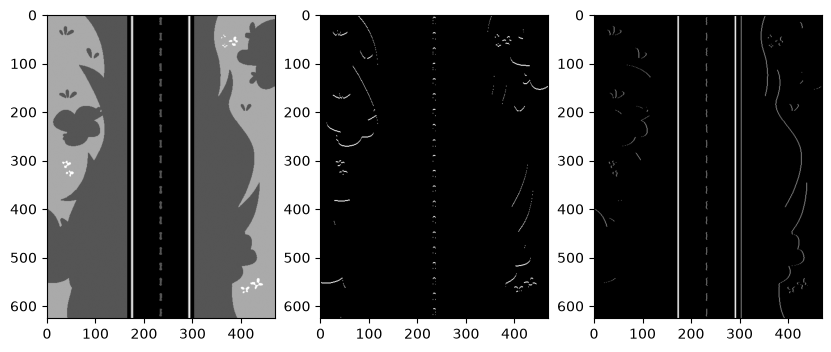

In [5]:


vertical_edges = cv.filter2D(filtered, -1, vertical_direction)
horizontal_edges = cv.filter2D(filtered, -1, horizontal_direction)
axes = plt.subplots(1, 3, figsize=(10, 5))[1]
axes[0].imshow(filtered, cmap='gray')
axes[1].imshow(vertical_edges, cmap='gray')
axes[2].imshow(horizontal_edges, cmap='gray')
plt.show()

- You can see the image processed by specific kernel of direction of gradient are different in the illustration of the line

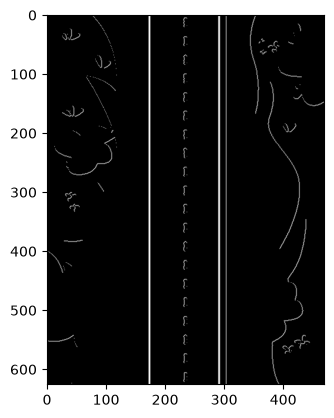

In [6]:
# Form an estimate of the image gradient
# Compute the magnitude of the gradient
gradient_magnitude = np.sqrt(vertical_edges**2 + horizontal_edges**2)
plt.imshow(gradient_magnitude, cmap='gray')
plt.show()

In [7]:
gradient_magnitude, horizontal_edges, vertical_edges

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(626, 470), dtype=float16),
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(626, 470), dtype=uint8),
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(626, 470), dtype=uint8))

Nếu như nó kiếm cấc vị trí vuông góc của gradietn thì mình có thể tìm theo hướng có thể dựa các trục của nó nếu như mà cấc hướng đó có thể là 44 độ thì có thể tìm cái hướng vuông góc đó nó sẽ ko trùng với cái hướng của tọa độ thì mình sẽ lợi dụng cái hướng mà có thể đánh giá được cái tọa độ đó dựa vào cái tính vô hướng nhân lại = 0 (orthogonal matrix) có thể đánh giá được điều trên nhưng có một cái nhược điểm là kiểu nếu tìm các hướng như x thig mình phải dựa vào cái gradient của vertilcal và horizontal ở trên nên mới xác định được cái hướng đó và sao khi khác định các hướng của gradient hoàn chỉnh thì nó có thể dựa vào các window trong hướng đó có vector gradient vuông góc sao khi tìm được vector đó thì tìm kiếm start point tại điểm đầu tiên ở điểm vuông góc và nếu như là nó thuộc local maximum thì lụm cx như là đánh dấu visited

Làm theo bước canny đầu tiên xử lí các hình ảnh theo gradient
- dùng bộ lộc sobel để phân biệt hay hướng và có thể đánh gía được hướng của gradient
Edge tracking by hyperthesis
- non suppersion: remove useless pixel
- double threhouse:double checking

In [8]:
sobelx = np.array(
    [[-1, 0, 1],
     [-2, 0, 2],
     [-1, 0, 1]]
)
sobely = np.array(
    [[-1, -2, -1],
     [0, 0, 0],
     [1, 2, 1]]
)

guassian_kernel = np.array([
    [1, 4, 6, 4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1, 4, 6, 4, 1]
]) / 256

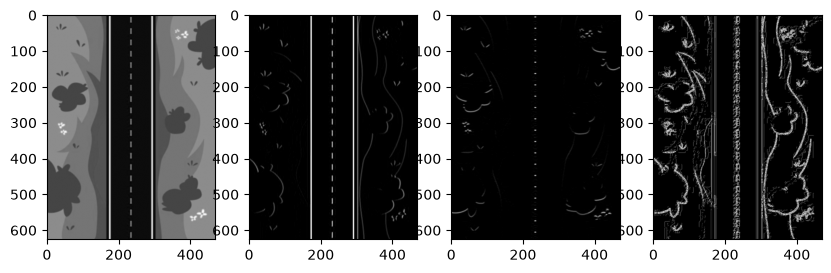

In [9]:
filtered = cv.filter2D(grey, -1, guassian_kernel)
Gx = cv.filter2D(filtered, -1, sobelx)
Gy = cv.filter2D(filtered, -1, sobely)
magnitude = np.sqrt(Gx**2 + Gy**2)
ax = plt.subplots(1, 4, figsize=(10, 5))[1]
ax[0].imshow(filtered, cmap='gray')
ax[1].imshow(Gx, cmap='gray')
ax[2].imshow(Gy, cmap='gray')
ax[3].imshow(magnitude, cmap='gray')
plt.show()

Cái này giuwsp tìm các hàng sóm và các corner
- Non maxiumum lấy các cạnh từ các hướng của gradient của nó 
- `ineterpolate`: tạo ra các data khác dựa trên các dãy đã biết trước đó 
- `linear interpolate`: phuwonag trình tuyến tính tính bằng `tan` bth
- `hysteresis`: dùng hai ngưỡng để giữ các large maxima

Non zero pixels in nonmax suppressed image: 36189, Non zero pixels in original image: 66429


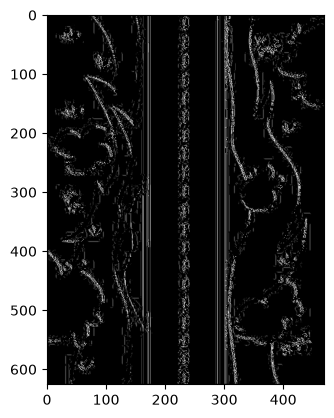

In [10]:
def nonmax_suppression(magnitude, Gx, Gy):
    theta = np.arctan2(Gy, Gx) * 180 / np.pi

    gmax = np.zeros_like(theta, dtype=np.uint8)

    direction_sections = np.array([0, 45, 90, 135]) # orientation sections for edge direction that has been quantized to 4 directionsarra
    array_directions = np.array([
        [[0, 0 ],   [0, -1]],
        [[-1,1 ],   [1, -1]],
        [[0, -1],   [1, 0 ]],
        [[1, -1],   [1, 1 ]]
    ])


    theta[theta < 0] += 180

    theta_delta = 10.5 # add more range in each direction section to avoid missing edges that are close to the boundary of the sections


    for i in range(theta.shape[0]):
        for j in range(theta.shape[1]):
            if (i + 1 < theta.shape[0] and j + 1 < theta.shape[1]):
                for k in range(len(direction_sections)):
                    if (direction_sections[k] - theta_delta <= theta[i, j] <= direction_sections[k] + theta_delta):
                        neighbor_index_1 = (i + array_directions[k][0][0], j + array_directions[k][0][1]) 
                        neighbor_index_2 = (i + array_directions[k][1][0], j + array_directions[k][1][1])
                        if (magnitude[i, j] >= magnitude[neighbor_index_1] and magnitude[i, j] >= magnitude[neighbor_index_2]):
                            gmax[i, j] = magnitude[i, j]

    return gmax
               




nonmax_suppressed = nonmax_suppression(magnitude, Gx, Gy)
print(f"Non zero pixels in nonmax suppressed image: {np.count_nonzero(nonmax_suppressed)}, Non zero pixels in original image: {np.count_nonzero(magnitude)}")
plt.imshow(nonmax_suppressed, cmap='gray')
plt.show()

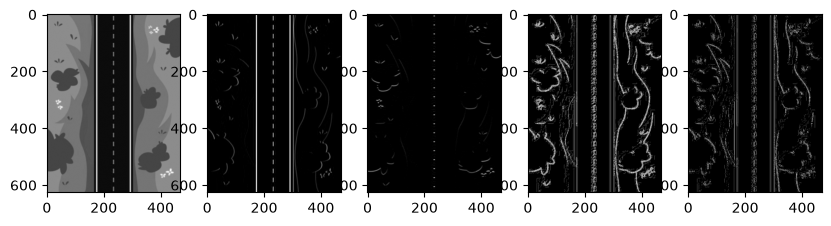

<Figure size 2000x500 with 0 Axes>

In [11]:

ax = plt.subplots(1, 5, figsize=(10, 5))[1]
ax[0].imshow(filtered, cmap='gray')
ax[1].imshow(Gx, cmap='gray')
ax[2].imshow(Gy, cmap='gray')
ax[3].imshow(magnitude, cmap='gray')
ax[4].imshow(nonmax_suppressed, cmap='gray')
plt.figure(figsize=(20, 5))
plt.show()

Edge tracking dùng để nối các điểm của cạnh yếu để có thể nối với cạnh mạnh để có thể nối các cạnh lại với nhau


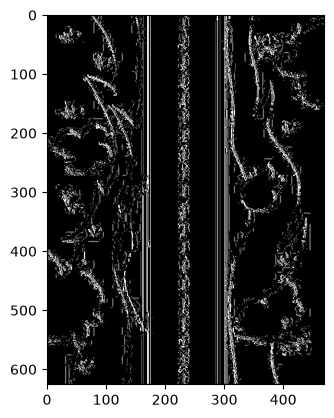

In [12]:
def hysteresis_thresholding(im):
    thre = np.zeros(im.shape)
    strong = 1
    weak = 0.5

    mmax = np.max(im)

    low_threshold = 0.1 * mmax
    high_threshold = 0.8 * mmax

    strongs = []

    for i in range(im.shape[0]):
        for j in range(im.shape[1]):
            if im[i, j] >= high_threshold:
                thre[i, j] = strong
                strongs.append((i, j))
            elif im[i, j] >= low_threshold:
                thre[i, j] = weak

    return thre, strongs

class edge_tracking:
    def __init__(self, im, strongs):
        self.im = im
        self.strongs = strongs
        self.visited = np.zeros(im.shape, dtype=bool)

    def track(self):
        for i, j in self.strongs:
            if not self.visited[i, j]:
                self.dfs(i, j)
        return self.im

    def dfs(self, i, j):
        if i < 0 or i >= self.im.shape[0] or j < 0 or j >= self.im.shape[1]:
            return
        if self.visited[i, j] or self.im[i, j] == 0:
            return

        self.visited[i, j] = True

        for di in range(-1, 2):
            for dj in range(-1, 2):
                ni, nj = i + di, j + dj
                if 0 <= ni < self.im.shape[0] and 0 <= nj < self.im.shape[1]:
                    if self.im[ni, nj] == 0.5:
                        self.im[ni, nj] = 1
                        self.dfs(ni, nj)



gmax, strongs = hysteresis_thresholding(nonmax_suppressed)
tracker = edge_tracking(gmax, strongs)
final_edges = tracker.track()
plt.imshow(final_edges, cmap='gray')
plt.show()





Orientation:
- Thông thường muốn tìm các cạnh để dùng các orientation để có thể ko bị ảnh hướng các ảnh có các kích thước khác nhau
- Nhưng cái phương pháp này ko hieeju quả khi dùng các hình ảnh đã làm smoothing vì sao khi smoothing thì nó làm mất đi các feature(pixel) mạnh để hình thành lên các cạnh mạnh

(array([239781.,   9573.,  18365.,   4101.,   2547.,   6200.,   2826.,
          4658.,   3533.,   2636.]),
 array([ 0.        ,  1.58105469,  3.16210938,  4.7421875 ,  6.32421875,
         7.90625   ,  9.484375  , 11.0703125 , 12.6484375 , 14.2265625 ,
        15.8125    ]),
 <BarContainer object of 10 artists>)

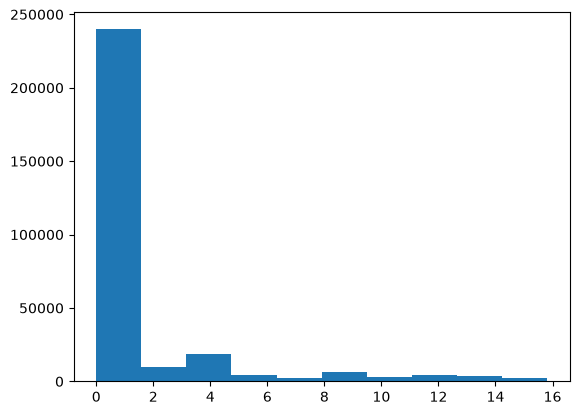

In [13]:
plt.hist(magnitude.flatten())

- Cách tìm corner thì có thể là không hiệu quả khi trong trong cạnh và các hướng orientation có thể là giải pháp khá tệ khi để vào cái các ảnh đã đượng smoothing 
- dùng engine value để hiểu đc tính chất ma trận để có thể tìm đc các gốc